In [1]:
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, os, datetime
pd.set_option('display.max_columns', None)

In [2]:
TEST    = json.loads(open('../info.json', 'r').read()).get('test', 1)
RESULTS = f'../Dataset/test{TEST}/results'
heave   = json.loads(open(f'{RESULTS}/heave.json', 'r').read())

print('SOURCE:', f'{RESULTS}/heave.csv', '|', heave['backup'])
heave

SOURCE: ../Dataset/test1/results/heave.csv | 4 - Heave/Backup/heave_2


{'strategy': 'heave',
 'backup': '4 - Heave/Backup/heave_2',
 'attitude': 'kalman_fusion',
 'pivot': [-0.1951779119, -1.9386759643, 0.0568038046],
 'trend': 10.0,
 'metrics': {'rms': 0.0205131702,
  'amplitude': 0.1582121066,
  'corr': 0.7678511709}}

# IMPORTANDO DADOS
- O heave do sensor e as bandas $H(s)s^2 R_{zj}$ do `4 - Heave`, com a atitude da referência para a verdade de qualquer ponto

In [3]:
df      = pd.read_csv(f'{RESULTS}/heave.csv').merge(pd.read_csv(f'{RESULTS}/corrected.csv', usecols=['time', 'ref_roll', 'ref_pitch', 'ref_yaw']), on='time')
PIVOT   = np.array(heave['pivot'])    # m, DO PIVÔ DO ENSAIO ATÉ O SENSOR
TREND   = heave['trend']              # s DA MÉDIA MÓVEL DA VERDADE, A MESMA DO 4 - Heave
SETTLE  = 20.0                        # s DO TRANSITÓRIO DE PARTIDA FORA DA MÉTRICA
GAP     = 0.5                         # s, O MESMO BURACO DO Section DO 4 - Heave
time    = df.time.to_numpy()
moving  = ~df.static.to_numpy()
window  = moving & (time > time[moving][0] + SETTLE)
segment = np.cumsum(np.r_[0, np.diff(time) > GAP])
length  = int(round(TREND / np.median(np.diff(time))))
df

,time,static,heave,heave_ref,band_x,band_y,band_z,ref_pitch,ref_roll,ref_yaw
0,0.0,False,0.000000,0.030163,0.000000,0.000000e+00,0.000000,0.304871,-71.390541,2.771970
1,0.1,False,-0.002453,0.074951,-0.001349,-1.649286e-02,-0.056734,0.337243,-76.661753,2.723841
2,0.2,False,-0.015224,0.106253,-0.002870,-3.250103e-02,-0.141519,0.366750,-82.677810,2.667691
3,0.3,False,-0.045848,0.115703,0.008065,-3.604018e-02,-0.244133,0.387721,-89.209529,2.743322
4,0.4,False,-0.094409,0.098720,0.003815,-2.249773e-02,-0.302400,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,-0.000940,0.000055,-0.000526,5.187891e-06,0.000211,1.644962,-92.131613,6.371291
1796,279.5,True,-0.000402,0.000055,-0.000574,8.627985e-06,0.000149,1.645535,-92.131613,6.371291
1797,279.6,True,0.000367,0.000052,-0.000132,5.120894e-07,0.000062,1.644962,-92.131613,6.371291
1798,279.7,True,0.001121,0.000052,0.000354,-1.030976e-05,0.000026,1.645535,-92.131613,6.377020


# TRANSLAÇÃO
- Um ponto a $d$ do MRU desce $(R\,d)_z$ além do sensor, e o heave dele passa pelo mesmo filtro: $h_P = h + H(s)s^2\,(R\,d)_z$
- $H$ é linear e $d$ é constante, então $H(s)s^2\,(R\,d)_z = \sum_j d_j\,H(s)s^2\,R_{zj}$: a translação é a combinação das três bandas da etapa 4, e o firmware faz a mesma conta passando $(R\,d)_z$ pelas duas seções
- No ensaio a verdade de qualquer ponto é o deslocamento rígido $(R_{ref}(r + d))_z$ em torno da mesma média móvel de `trend` s do `4 - Heave`

In [4]:
R = Rotation.from_euler('xyz', df[['ref_roll', 'ref_pitch', 'ref_yaw']].to_numpy(), degrees=True).as_matrix()


# HEAVE NO PONTO d PELAS BANDAS E A VERDADE DELE PELO PIVÔ DO ENSAIO
def translate(d):
    geo   = R[:, 2, :] @ (PIVOT + d)
    truth = geo - pd.Series(geo).groupby(segment).transform(lambda part: part.rolling(length, center=True, min_periods=1).mean()).to_numpy()
    return df.heave.to_numpy() + df[['band_x', 'band_y', 'band_z']].to_numpy() @ d, truth


translate(np.zeros(3))[0][:5]

array([ 0.        , -0.00245294, -0.0152236 , -0.04584819, -0.09440888])

# VALIDAÇÃO
- O pivô não se mexe ($d = -r$), o sensor é a própria etapa 4 ($d = 0$) e um ponto além dele dobra o braço ($d = r$)

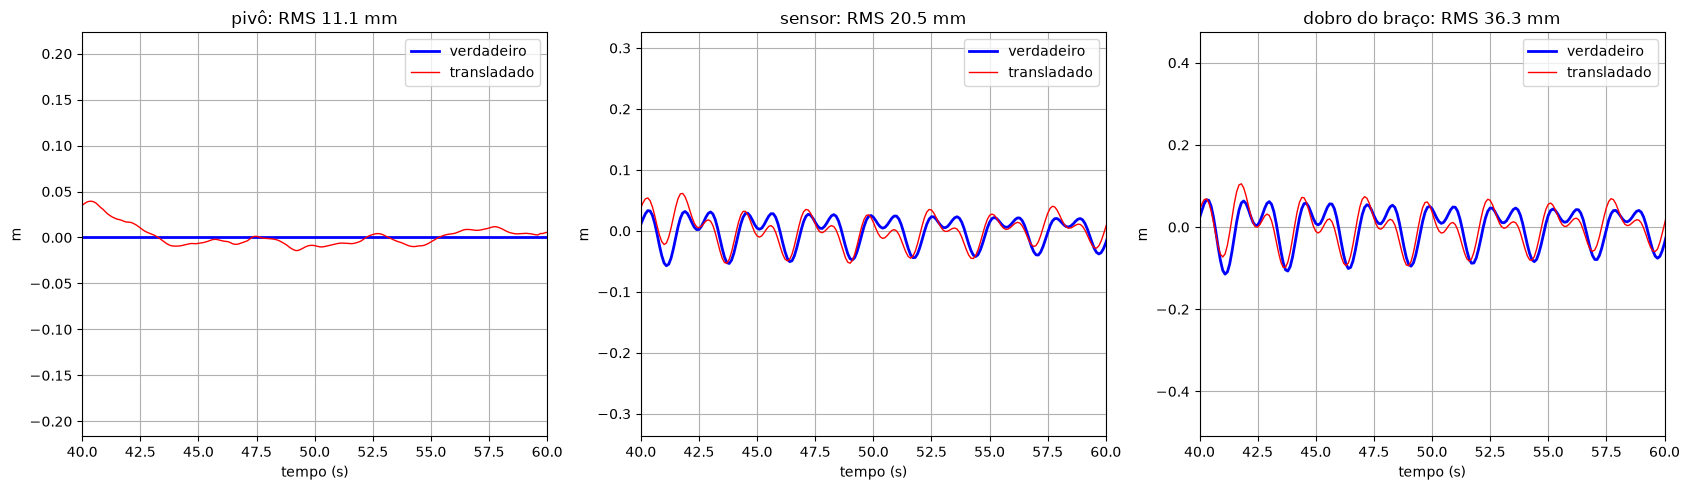

,rms (mm),amplitude (mm)
pivô,11.1,0.0
sensor,20.5,158.2
dobro do braço,36.3,316.4


In [5]:
POINTS = {'pivô': -PIVOT, 'sensor': np.zeros(3), 'dobro do braço': PIVOT}
plot   = np.where(moving, time, np.nan)

plt.figure(figsize=(17, 5))
metrics = {}

for i, (name, d) in enumerate(POINTS.items()):
    estimate, truth = translate(d)
    metrics[name]   = {'rms (mm)': 1000*np.sqrt(np.mean((estimate - truth)[window]**2)), 'amplitude (mm)': 1000*np.ptp(truth[window])}

    plt.subplot(1, 3, i + 1)
    plt.plot(plot, truth, label='verdadeiro', color='blue', linewidth=2)
    plt.plot(plot, estimate, label='transladado', color='red', linewidth=1)
    plt.xlim(40, 60)
    plt.title(f'{name}: RMS {metrics[name]["rms (mm)"]:.1f} mm'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()

plt.tight_layout()
plt.show()
pd.DataFrame(metrics).T.round(1)

# PONTO DE INTERESSE
- `POINT` é a distância do MRU até o ponto que a norma cobra, o centro da área de pouso do helideque, nos eixos do navio com $z$ para baixo; sai do desenho da embarcação
- Com `POINT` nulo o MRU entrega o heave dele mesmo
- A velocidade de arfagem (VArf da NORMAM) sai como no firmware: a diferença do heave no ponto entre amostras, zero na partida e depois de buraco; o heave já sai suave da integração, então a diferença não amplifica ruído

In [6]:
POINT = np.array([0.0, 0.0, 0.0])    # m, DO MRU ATÉ O PONTO DE INTERESSE


# VELOCIDADE DE ARFAGEM COMO O firmware: DIFERENÇA ENTRE AMOSTRAS, ZERO NA PARTIDA E DEPOIS DE BURACO
def getRate(values):
    step = np.diff(time, prepend=time[0])
    return np.where((step > 0) & (step <= GAP), np.diff(values, prepend=values[0]) / np.where(step > 0, step, 1), 0.0)


estimate, truth = translate(POINT)
lever           = df[['time', 'static']].assign(heave=estimate, heave_ref=truth, hr=getRate(estimate), hr_ref=getRate(truth))
print(f'heave {1000*np.sqrt(np.mean((lever.heave - lever.heave_ref)[window]**2)):.1f} mm | hr {1000*np.sqrt(np.mean((lever.hr - lever.hr_ref)[window]**2)):.1f} mm/s RMS')

lever.to_csv(f'{RESULTS}/lever.csv', index=None)
lever

heave 20.5 mm | hr 50.4 mm/s RMS


,time,static,heave,heave_ref,hr,hr_ref
0,0.0,False,0.000000,0.030163,0.000000,0.000000
1,0.1,False,-0.002453,0.074951,-0.024529,0.447882
2,0.2,False,-0.015224,0.106253,-0.127707,0.313017
3,0.3,False,-0.045848,0.115703,-0.306246,0.094507
4,0.4,False,-0.094409,0.098720,-0.485607,-0.169831
...,...,...,...,...,...,...
1795,279.4,True,-0.000940,0.000055,0.002080,-0.000015
1796,279.5,True,-0.000402,0.000055,0.005380,-0.000002
1797,279.6,True,0.000367,0.000052,0.007683,-0.000030
1798,279.7,True,0.001121,0.000052,0.007543,-0.000003


In [7]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('lever_')]
index  = len(saved) + 1

output = f'Backup/lever_{index}'
os.makedirs(output, exist_ok=True)

results = {
    'point':      POINT.tolist(),
    'pivot':      PIVOT.tolist(),
    'validation': metrics,
    'metrics':    {'rms': float(np.sqrt(np.mean((estimate - truth)[window]**2))), 'rms_rate': float(np.sqrt(np.mean((lever.hr - lever.hr_ref)[window]**2)))},
    'dataset':    {'path': f'{RESULTS}/heave.csv', 'samples': len(df), 'settle': SETTLE}
}

record = {
    'strategy': 'lever',
    'backup':   f'5 - Lever/{output}',
    'point':    POINT.tolist(),
    'metrics':  results['metrics']
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
pd.Series(record).to_json(f'{RESULTS}/lever.json', indent=4)
print(output, '->', f'{RESULTS}/lever.json')
record

Backup/lever_2 -> ../Dataset/test1/results/lever.json


{'strategy': 'lever',
 'backup': '5 - Lever/Backup/lever_2',
 'point': [0.0, 0.0, 0.0],
 'metrics': {'rms': 0.020513170173545224, 'rms_rate': 0.05040689795771078}}

# EXPORTANDO PARA O FIRMWARE
- O firmware passa $(R\,d)_z$ pelas duas seções passa-alta do `HEAVE_PERIOD` e soma ao heave do sensor

In [8]:
FIRMWARE = '../../Hardware/Embedded/Main/objects/processing/lever'
point    = ', '.join(f'{value:.6f}f' for value in POINT)

header = f'''#ifndef LEVER_CONFIG_H
#define LEVER_CONFIG_H

// GERADO POR Calibration/5 - Lever/1 - Model.ipynb EM {datetime.date.today():%d/%m/%Y}
static const float LEVER_POINT[3] = {{{point}}};    // m, do MRU ate o ponto de interesse nos eixos do navio (z para baixo)

#endif
'''

open(f'{FIRMWARE}/config.h', 'w').write(header)
print(header)

#ifndef LEVER_CONFIG_H
#define LEVER_CONFIG_H

// GERADO POR Calibration/5 - Lever/1 - Model.ipynb EM 15/10/2026
static const float LEVER_POINT[3] = {0.000000f, 0.000000f, 0.000000f};    // m, do MRU ate o ponto de interesse nos eixos do navio (z para baixo)

#endif

